# Dipole orientation
Run in your local OneSimulation environment. Compare the exact integral with the weak-field approximation, then vary the Gaussian quadrature order.

Maximum quadrature error: 8.88e-16
pE/kT =  0.2, <cos(theta)> = 0.066490, linear = 0.066667
pE/kT =  1.0, <cos(theta)> = 0.313035, linear = 0.333333
pE/kT =  3.0, <cos(theta)> = 0.671636, linear = 1.000000
pE/kT = 10.0, <cos(theta)> = 0.900000, linear = 3.333333


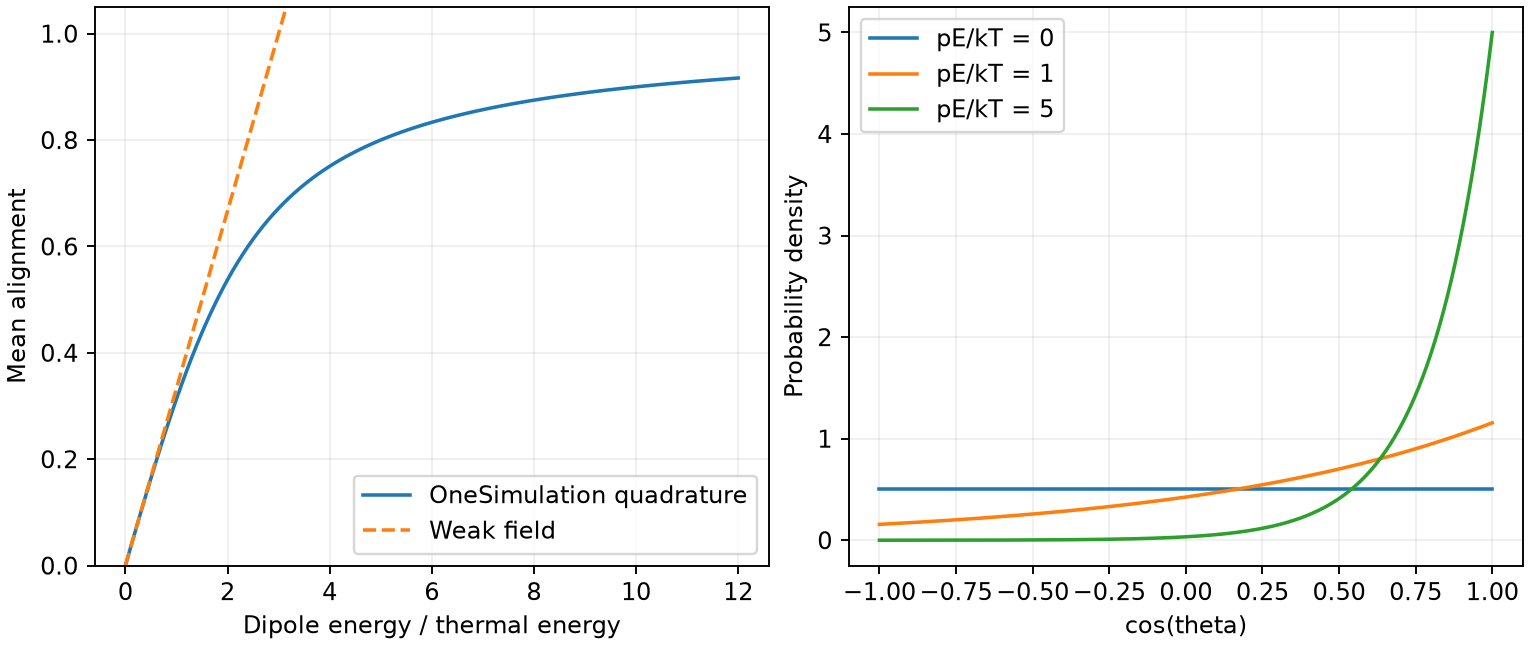

In [1]:
"""Orient freely rotating permanent dipoles and compare quadrature with the exact law."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigensystem

# The eigenvectors give Gaussian weights for the integral over u = cos(theta).
order = 32
indices = np.arange(1, order, dtype=float)
off_diagonal = indices / np.sqrt(4 * indices**2 - 1)
jacobi = np.diag(off_diagonal, 1) + np.diag(off_diagonal, -1)
nodes, vectors = symmetric_eigensystem(jacobi)
weights = 2 * vectors[0, :]**2
field_energy = np.linspace(0, 12, 121)  # x = p E / (k_B T)
mean_alignment = []
for x in field_energy:
    probability = weights * np.exp(x * (nodes - 1))
    mean_alignment.append(np.dot(nodes, probability) / probability.sum())
mean_alignment = np.asarray(mean_alignment)
exact = np.zeros_like(field_energy)
exact[1:] = 1 / np.tanh(field_energy[1:]) - 1 / field_energy[1:]
print(f"Maximum quadrature error: {np.max(abs(mean_alignment - exact)):.2e}")
for x in (0.2, 1.0, 3.0, 10.0):
    index = np.argmin(abs(field_energy - x))
    print(f"pE/kT = {x:4.1f}, <cos(theta)> = {mean_alignment[index]:.6f}, linear = {x/3:.6f}")
assert np.max(abs(mean_alignment - exact)) < 1e-12
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
axes[0].plot(field_energy, mean_alignment, label="OneSimulation quadrature")
axes[0].plot(field_energy, field_energy / 3, "--", label="Weak field")
axes[0].set(xlabel="Dipole energy / thermal energy", ylabel="Mean alignment", ylim=(0, 1.05))
axes[0].legend()
for x in (0, 1, 5):
    u = np.linspace(-1, 1, 301)
    normalizer = 2 if x == 0 else 2*np.sinh(x)/x
    axes[1].plot(u, np.exp(x*u)/normalizer, label=f"pE/kT = {x}")
axes[1].set(xlabel="cos(theta)", ylabel="Probability density")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=.2)
fig.savefig("electrodynamics-orientation.png", dpi=170)
